# Pickleball — ba mục tiêu và bằng chứng
Notebook này dùng video tổng hợp có bóng vàng để kiểm tra thuật toán. Không phải kết quả nhận diện trên trận thật. Xem reports/project-audit.md để phân biệt chức năng đã có và nghiên cứu còn thiếu.

In [1]:
from pathlib import Path
import sys
ROOT=Path.cwd()
if not (ROOT/"rally_evidence.py").exists(): ROOT=ROOT.parent
sys.path.insert(0,str(ROOT))
import cv2, numpy as np, pandas as pd
from IPython.display import display, Video, Image
from rally_evidence import track_ball, rallies_from_events, timecode_table, rally_metrics
from photo_finish import finish_photo
from core import export_video
OUT=ROOT/"runs"/"project_notebook"
OUT.mkdir(parents=True,exist_ok=True)

## 1. Ứng viên bóng và quỹ đạo ở FPS gốc
HSV + sai khác khung + lọc kích thước/hình dạng; nối theo dự đoán vận tốc. Đổi hướng chỉ là ứng viên sự kiện. Chưa có detector mặt vợt/sàn. Phần trăm khung observed không phải accuracy.

In [2]:
source=OUT/"synthetic_ball.mp4"
writer=cv2.VideoWriter(str(source),cv2.VideoWriter_fourcc(*"mp4v"),24,(320,240))
for i in range(96):
    frame=np.full((240,320,3),30,np.uint8)
    x=30+int(3*i) if i<48 else 174-int(2*(i-48))
    cv2.circle(frame,(x,120),5,(0,255,255),-1)
    writer.write(frame)
writer.release()
tracks,events,overlay,diagnostics=track_ball(source,0,4,OUT/"evidence")
display(tracks.head())
print(diagnostics)
display(Video(str(overlay),embed=True))

,frame,time,x,y,observed,track_id,candidate_count
0,0,0.000000,30.102564,120.012821,True,1,1
1,1,0.041667,33.518519,120.018519,True,1,1
2,2,0.083333,36.814815,120.018519,True,1,1
3,3,0.125000,39.518519,120.018519,True,1,1
4,4,0.166667,42.814815,120.018519,True,1,1


{'fps': 24.0, 'start': 0, 'end': 4, 'roi': [0.0, 0.0, 1.0, 1.0], 'hue': [18, 48], 'frames': 96, 'observation_fraction': 1.0, 'event_candidates': 1, 'warning': 'Observation fraction is not detection accuracy. No paddle/floor detector.'}


## 2. Sự kiện → pha → ghép toàn bộ và timecode
Nhãn dưới đây chỉ minh họa máy trạng thái, không được suy từ chấm vàng. Một lần bóng nảy hoặc mất dấu không tự kết thúc pha. Chỉ serve/rally_end đã xác nhận đóng cặp; pha mở bị báo thiếu bằng chứng.

In [3]:
labels=[{"time":.2,"kind":"serve","confirmed":True}, {"time":1.,"kind":"bounce","confirmed":True}, {"time":2.,"kind":"paddle_contact","confirmed":True}, {"time":3.8,"kind":"rally_end","confirmed":True}]
rallies,warnings=rallies_from_events(labels,4)
print(warnings)
display(timecode_table(rallies))
result=export_video(source,rallies,OUT/"confirmed")
display(Video(str(result),embed=True))
print(rally_metrics([(r["start"],r["end"]) for r in rallies],[(.25,3.7)]))

[]


,rally,source_start,source_end,highlight_start,highlight_end
0,1,0.2,3.8,0.0,3.6


{'precision': 1.0, 'recall': 1.0, 'f1': 1.0, 'matched': 1, 'predicted': 1, 'reference': 1, 'start_mae_seconds': 0.04999999999999999, 'end_mae_seconds': 0.09999999999999964}


## 3. Bộ lọc ảnh tùy chọn
Video tổng hợp không có vận động viên; ô này chỉ kiểm tra xuất ảnh và thông số. Với video thật phải chọn góc ngang có sẵn, khoanh vận động viên và đoạn ≤20 giây. NLM + unsharp; Wiener tùy chọn giả định PSF vệt thẳng. Sai PSF có thể tạo viền giả; luôn giữ ảnh gốc để so sánh.

{'time': 0.041666666666666664, 'start': 0, 'end': 1, 'roi': [0.0, 0.0, 1.0, 1.0], 'width': 320, 'height': 240, 'input_laplacian_variance': 71.88760416666666, 'denoise': 3, 'unsharp_amount': 0.7, 'wiener_psf_length': 0, 'wiener_psf_angle': 0.0, 'wiener_regularization': 0.03, 'view': 'user_selected_side_view', 'note': 'Sharpness score is not perceptual quality. No new viewpoint or details synthesized.'}


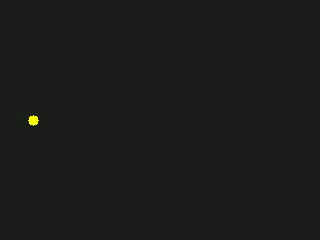

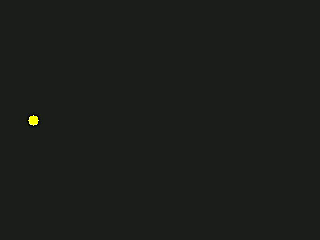

In [4]:
original,enhanced,metadata=finish_photo(source,0,1,OUT/"photo",sharpen=.7,denoise=3)
print(metadata)
display(Image(filename=str(original)))
display(Image(filename=str(enhanced)))

## 4. Đánh giá và báo cáo
Tách validation/test theo trận. Chấm tọa độ bóng, sự kiện và mốc pha độc lập. Đo recall/precision bóng với tolerance pixel, event F1, rally IoU F1 và MAE ranh giới. So sánh baseline chuyển động, camera+âm thanh, kết quả sau duyệt, cùng bộ nhãn. Đối với ảnh, khảo sát mù trước/sau; Laplacian variance không phải điểm chất lượng ảnh. Chưa có bằng chứng contact detector tự động nên không kết luận mục tiêu 1 đã hoàn tất.